# PR11: Advanced Machine Learning and Model Optimization

**Aim:** Implement SVM, Random Forest and AdaBoost; apply 5-fold cross-validation and Grid Search; compare performance before and after tuning.

**Dataset:** Pima Indians Diabetes dataset (same as the original notebook).

In [2]:
import pandas as pd

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, f1_score


## 1. Import libraries and load dataset

In [3]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columns = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
           "BMI", "DiabetesPedigree", "Age", "Outcome"]
df = pd.read_csv(url, names=columns)

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
df.head()

Dataset shape: (768, 9)
Missing values: 0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Split the data and define models

In [4]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [5]:
models = {
    "SVM": make_pipeline(StandardScaler(), SVC()),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

parameters = {
    "SVM": {"svc__C": [1, 10], "svc__kernel": ["linear", "rbf"]},
    "Random Forest": {"n_estimators": [50, 100]},
     # Number of decision trees
    "AdaBoost": {"n_estimators": [50, 100]}
    # Number of Weak Learners
}

## 3. Cross-validation, Grid Search and evaluation

For each model, calculate 5-fold CV accuracy and test accuracy/F1 **before** tuning. Then use Grid Search (5-fold CV) and calculate scores **after** tuning. Scaling is included inside the SVM pipeline so each CV fold is handled correctly.

In [6]:
results = []

for name, model in models.items():

    # Before optimization
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    cv = cross_val_score(model, X_train, y_train, cv=5).mean()

    acc1 = accuracy_score(y_test, pred)
    f1_1 = f1_score(y_test, pred)

    # After optimization
    grid = GridSearchCV(model, parameters[name], cv=5)
    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    pred = best_model.predict(X_test)

    acc2 = accuracy_score(y_test, pred)
    f1_2 = f1_score(y_test, pred)

    results.append([name, cv, acc1, f1_1, grid.best_score_, acc2, f1_2])

    print(name, grid.best_params_)

comparison = pd.DataFrame(results, columns=[
    "Model", "CV Before", "Accuracy Before", "F1 Before",
    "CV After", "Accuracy After", "F1 After"
])

print(comparison.round(4))

SVM {'svc__C': 1, 'svc__kernel': 'linear'}
Random Forest {'n_estimators': 100}
AdaBoost {'n_estimators': 100}
           Model  CV Before  Accuracy Before  F1 Before  CV After  \
0            SVM     0.7524           0.7532     0.6346    0.7753   
1  Random Forest     0.7655           0.7597     0.6337    0.7655   
2       AdaBoost     0.7655           0.7792     0.6731    0.7671   

   Accuracy After  F1 After  
0          0.7208    0.5657  
1          0.7597    0.6337  
2          0.7922    0.6923  


## 4. Compare results and conclude

Best model before tuning: AdaBoost
Best model after tuning: AdaBoost


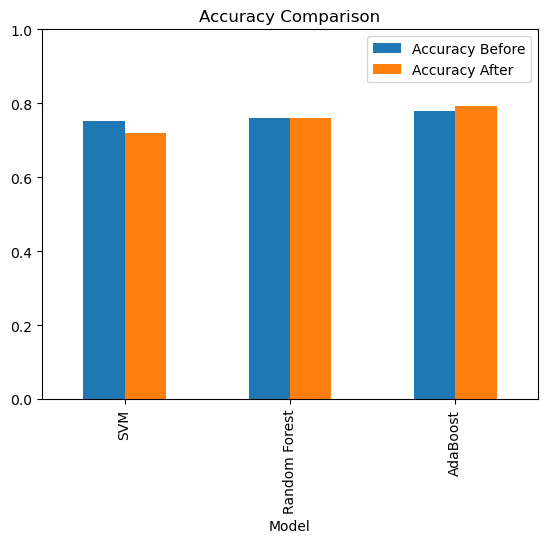

In [8]:
best_before = comparison.loc[comparison["Accuracy Before"].idxmax(), "Model"]
best_after = comparison.loc[comparison["Accuracy After"].idxmax(), "Model"]

print("Best model before tuning:", best_before)
print("Best model after tuning:", best_after)

comparison.plot(x="Model", y=["Accuracy Before", "Accuracy After"],
                kind="bar", ylim=(0, 1), title="Accuracy Comparison");